# Olist E-Commerce Analytics: SQL + Python

Analysis of about 100,000 real orders placed on the Olist marketplace in Brazil (2016 to 2018). All metrics are computed in SQL with DuckDB; Python handles orchestration, statistical testing, and charts.

**Questions**
1. How did revenue evolve, and where does it come from?
2. Do customers come back?
3. How much does delivery performance affect customer satisfaction?
4. How concentrated is the seller base?
5. How do customers pay?

Revenue means item price of **delivered** orders in Brazilian reais (R$), excluding freight. Trends use January 2017 to August 2018, because 2016 has fewer than 300 orders.

In [1]:
import os
from pathlib import Path
from IPython.display import Image, display
import pandas as pd

os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
from src.build_database import build

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 140
con = build()

def run(name):
    sql = Path(f"sql/analysis/{name}.sql").read_text()
    return con.execute(sql).fetchdf()

def show(name):
    display(Image(f"reports/figures/{name}.png", width=760))

## 1. Data loading and quality checks

Eight CSV files are loaded into typed DuckDB tables (`sql/01_schema.sql`). Views (`sql/02_views.sql`) deduplicate reviews to one per order and build a `delivered_orders` table with delivery metrics. Checks below are in `sql/03_data_quality.sql`.

In [2]:
for t in ["customers", "orders", "order_items", "order_payments", "order_reviews", "products", "sellers"]:
    print(f"{t:16s}{con.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0]:>9,}")
print()
con.execute(open("sql/03_data_quality.sql").read()).fetchdf()

customers          99,441
orders             99,441
order_items       112,650
order_payments    103,886
order_reviews      99,224
products           32,951
sellers             3,095



,check_name,issues,rows_checked
0,orders: duplicate order_id,0,99441
1,orders: customer_id missing in customers,0,99441
2,order_items: order_id missing in orders,0,112650
3,order_items: product_id missing in products,0,112650
4,order_items: seller_id missing in sellers,0,112650
5,orders: no items (any status),775,99441
6,orders: delivered but no delivery date,8,96478
7,orders: delivered before purchase,0,96476
8,order_reviews: orders with more than one review,547,98673
9,order_reviews: review_score outside 1-5,0,99224


Referential integrity is clean: no orphan keys and no duplicate order IDs. Three issues needed handling:

- **775 orders have no items**, almost all of them cancelled or unavailable, so they carry no revenue.
- **8 orders are marked delivered but have no delivery date**, so they are excluded from delivery analysis.
- **547 orders have more than one review.** Each order keeps only its latest review so that scores are not double counted.

## 2. Revenue over time

In [3]:
run("10_monthly_revenue")

,month,orders,revenue,freight,avg_order_value,revenue_mom_pct,revenue_3m_avg
0,2017-01,750,"111,798.00","15,684.00",149.06,NaN,"111,798.00"
1,2017-02,1653,"234,223.00","37,016.00",141.70,109.50,"173,011.00"
2,2017-03,2546,"359,199.00","55,132.00",141.08,53.40,"235,074.00"
3,2017-04,2303,"340,670.00","50,143.00",147.92,-5.20,"311,364.00"
4,2017-05,3545,"489,159.00","77,498.00",137.99,43.60,"396,343.00"
5,2017-06,3135,"421,923.00","68,127.00",134.58,-13.70,"417,251.00"
6,2017-07,3872,"481,605.00","84,695.00",124.38,14.10,"464,229.00"
7,2017-08,4193,"554,700.00","91,133.00",132.29,15.20,"486,076.00"
8,2017-09,4150,"607,400.00","93,678.00",146.36,9.50,"547,901.00"
9,2017-10,4478,"648,248.00","102,869.00",144.76,6.70,"603,449.00"


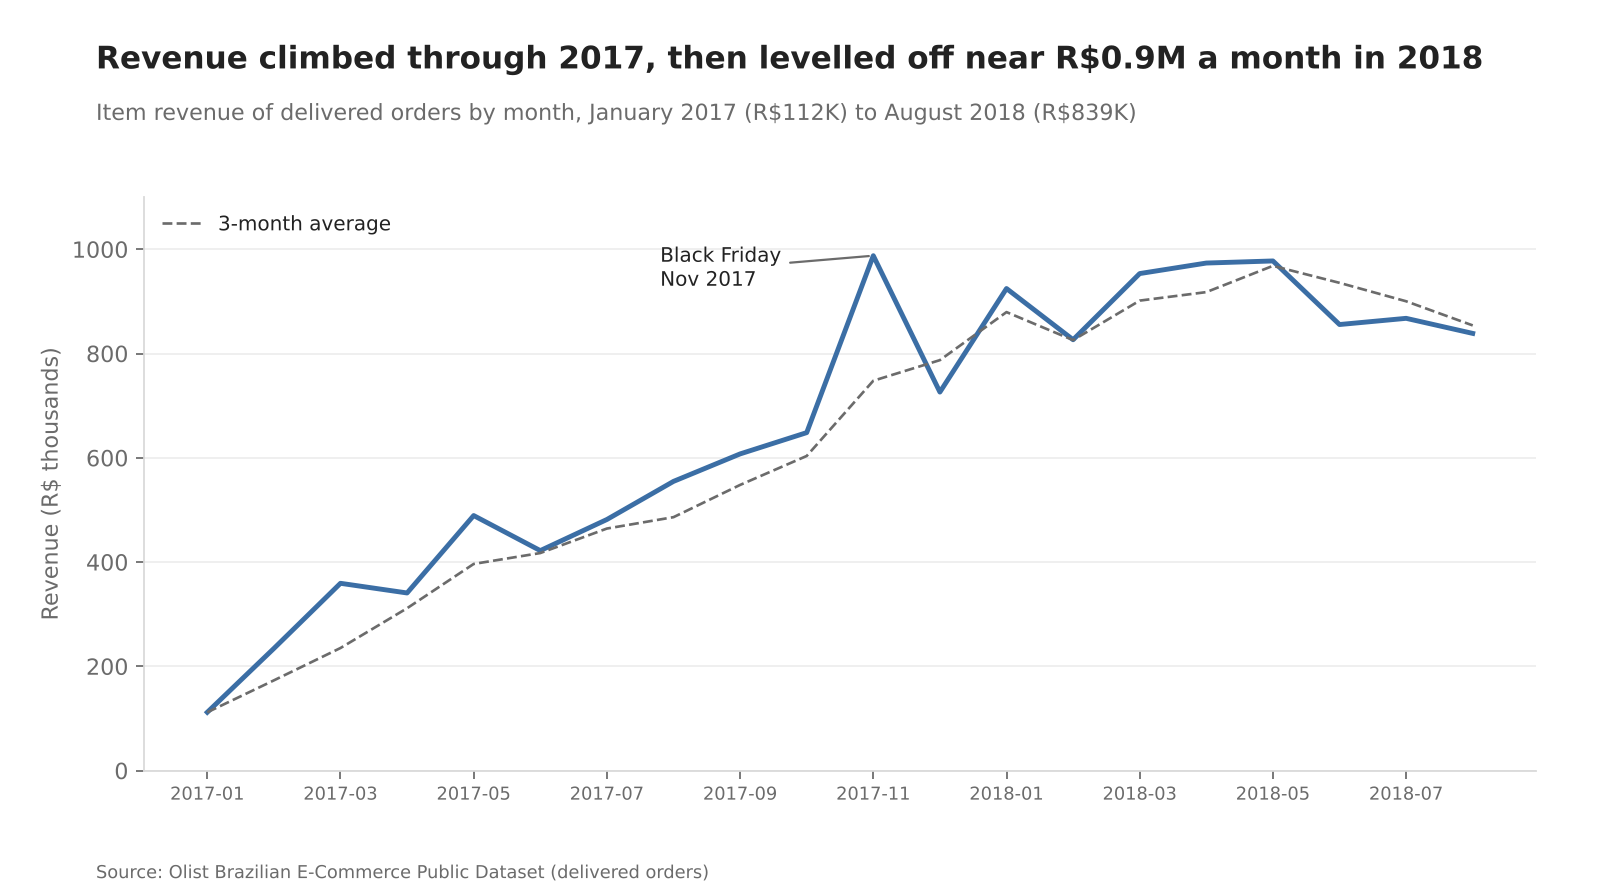

In [4]:
show("01_monthly_revenue")

Revenue rose steadily through 2017 and peaked in **November 2017** (R$987,648, up 52.4% on October), the Black Friday month, then fell 26.5% in December. In 2018 it flattened: monthly revenue stayed between R$826K and R$978K from January to August. Average order value stayed in a narrow R$124 to R$149 band over the whole period, so growth came from order volume, not larger baskets.

## 3. Product categories

In [5]:
run("11_category_performance").head(10)

,revenue_rank,category,orders,items_sold,revenue,revenue_share_pct,cumulative_share_pct,avg_item_price,avg_review_score
0,1,health_beauty,8647,9465,"1,233,132.00",9.33,9.33,130.28,4.19
1,2,watches_gifts,5493,5857,"1,165,899.00",8.82,18.15,199.06,4.07
2,3,bed_bath_table,9272,10953,"1,023,435.00",7.74,25.89,93.44,3.92
3,4,sports_leisure,7529,8430,"954,674.00",7.22,33.11,113.25,4.17
4,5,computers_accessories,6529,7643,"888,614.00",6.72,39.83,116.27,3.99
5,6,furniture_decor,6307,8160,"711,928.00",5.39,45.22,87.25,3.95
6,7,housewares,5743,6795,"615,629.00",4.66,49.87,90.60,4.11
7,8,cool_stuff,3559,3718,"610,204.00",4.62,54.49,164.12,4.20
8,9,auto,3809,4139,"578,849.00",4.38,58.87,139.85,4.11
9,10,toys,3803,4029,"471,097.00",3.56,62.43,116.93,4.21


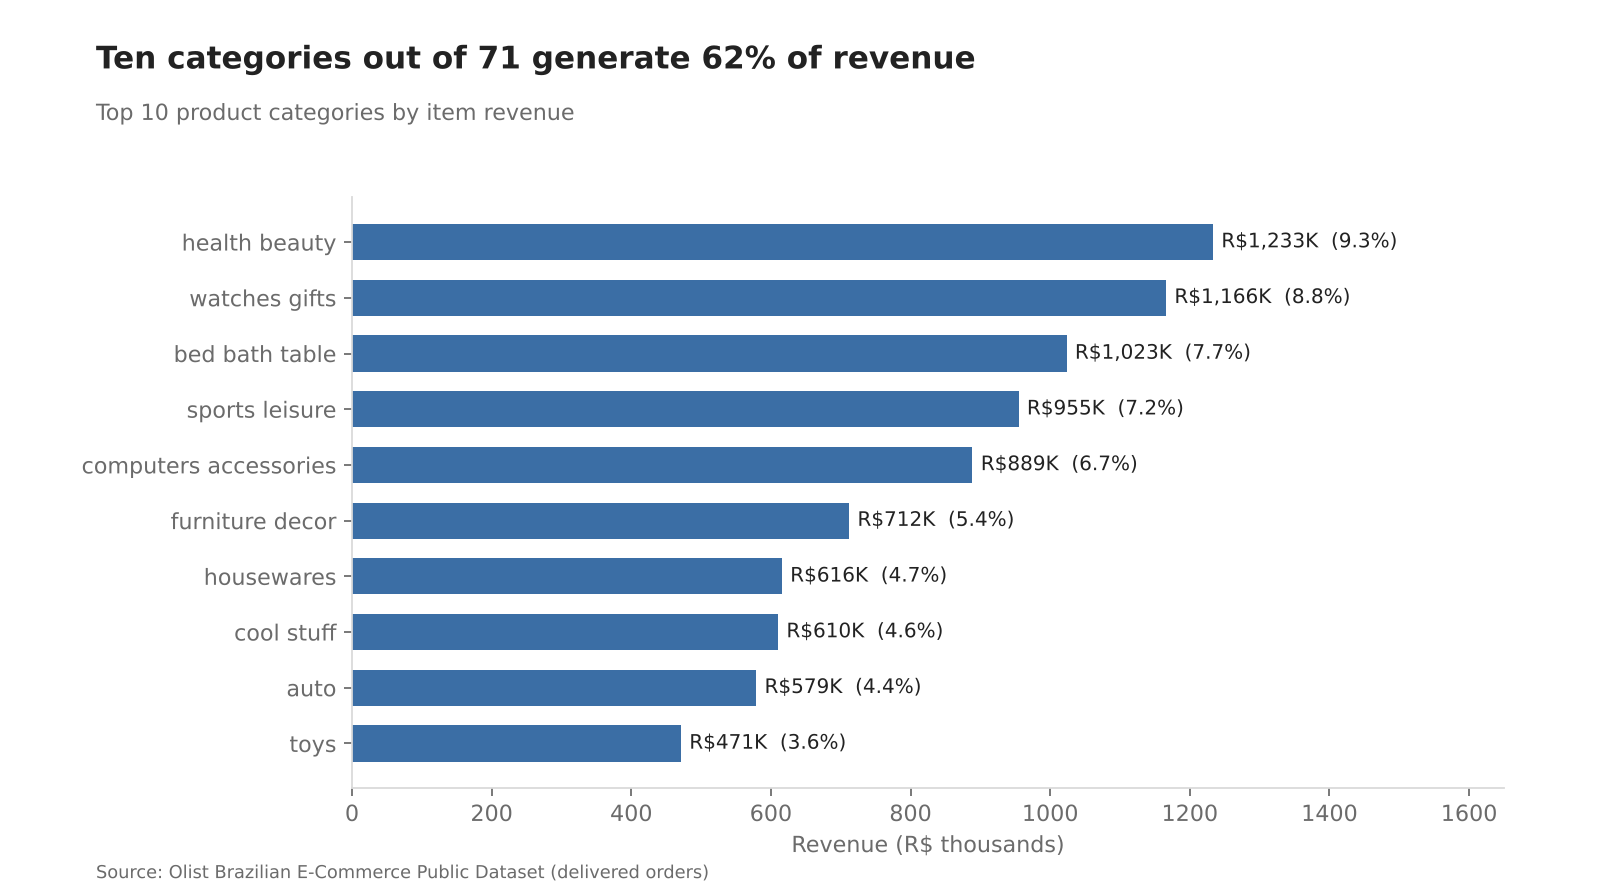

In [6]:
show("02_top_categories")

The top 10 of 71 categories generate **62.4%** of revenue. `health_beauty` leads with 9.3%. `watches_gifts` ranks second with the highest average item price among the leaders (R$199), while `bed_bath_table` has the most orders (9,272) but the lowest review score among the top five categories (3.92).

## 4. Do customers come back?

In [7]:
run("12a_repeat_purchase")

,orders_placed,customers,customers_pct,revenue,revenue_pct
0,1,90549,97.00,"12,491,840.00",94.49
1,2,2573,2.76,"631,275.00",4.78
2,3+,228,0.24,"97,134.00",0.73


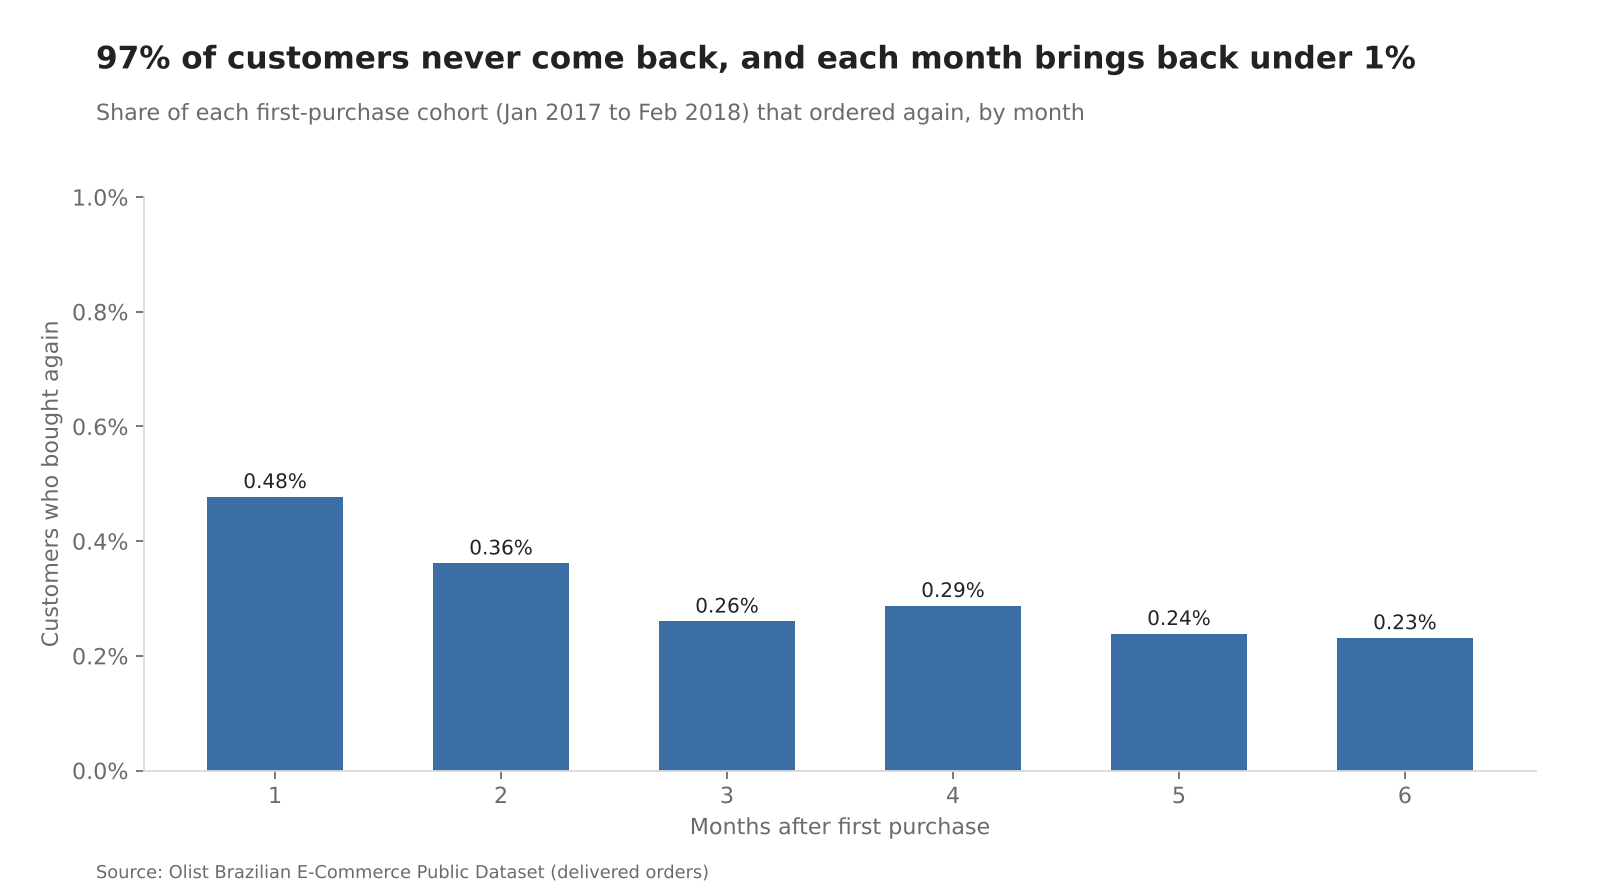

In [8]:
show("03_retention")

**97.0% of customers placed exactly one order.** Repeat customers (3.0% of the base) generate only 5.5% of revenue. Cohort retention confirms the pattern: across the January 2017 to February 2018 cohorts combined, 0.48% buy again in month one, falling to 0.23% by month six, and no single cohort in any month exceeds 0.72%. Olist behaves like a one-shot marketplace, so acquisition, not retention, drives its revenue.

RFM segmentation below should be read with that in mind: with so few repeat buyers, the frequency dimension separates very little, so the segments are driven mostly by recency and spend.

In [9]:
run("13_rfm_segments")

,segment,customers,customers_pct,revenue,revenue_pct,avg_spend,avg_recency_days
0,Lapsed big spenders,10329,11.06,"4,089,138.00",30.93,395.89,341.00
1,Dormant one-time buyers,44081,47.22,"3,330,878.00",25.20,75.56,337.00
2,Recent big spenders,6923,7.42,"2,820,542.00",21.34,407.42,92.00
3,Recent one-time buyers,29216,31.30,"2,251,283.00",17.03,77.06,91.00
4,Lapsed repeat buyers,1600,1.71,"403,251.00",3.05,252.03,320.00
5,Active repeat buyers,1201,1.29,"325,158.00",2.46,270.74,89.00


The largest revenue pool (30.9%) sits in **lapsed big spenders**: 10,329 customers in the top spend quintile who last bought on average 341 days before the end of the data.

## 5. Delivery performance and customer satisfaction

In [10]:
run("14a_delivery_vs_review")

,delivery_outcome,orders,orders_pct,avg_delivery_days,avg_review_score,one_star_pct,five_star_pct
0,On time or early,89443,93.34,11.00,4.29,6.60,62.30
1,Late,6381,6.66,33.80,2.27,53.80,16.50


In [11]:
run("14b_lateness_buckets")

,bucket,orders,avg_review_score,one_star_pct
0,1. 8+ days early,70929,4.32,6.50
1,2. 1-7 days early,17234,4.20,7.10
2,3. On the estimated day,1280,4.03,8.50
3,4. 1-3 days late,1852,3.29,25.10
4,5. 4-7 days late,1748,2.10,58.60
5,6. 8+ days late,2781,1.70,69.80


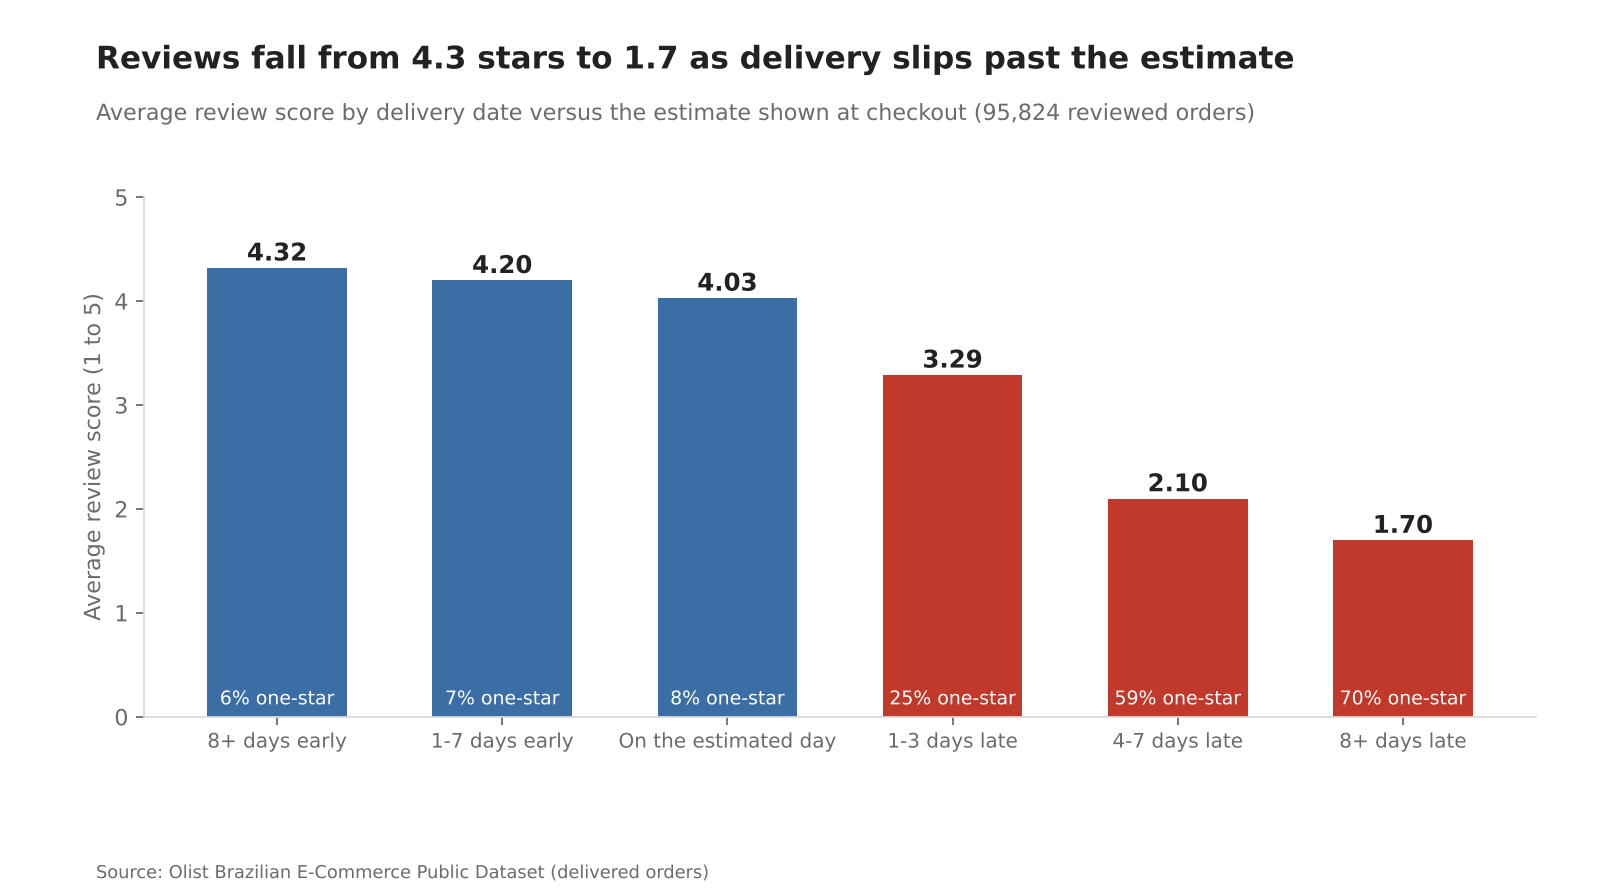

In [12]:
show("04_lateness_vs_reviews")

Is the gap statistically meaningful? `src/stats_tests.py` runs a Mann-Whitney U test (review scores are ordinal), a bootstrap confidence interval for the mean difference, and a Spearman correlation.

In [13]:
import json
print(json.dumps(json.load(open("reports/results/stats_summary.json")), indent=2))

{
  "n_reviewed_orders": 95824,
  "n_late": 6381,
  "n_on_time": 89443,
  "mean_score_on_time": 4.29,
  "mean_score_late": 2.27,
  "mean_difference": 2.02,
  "bootstrap_95ci_difference": [
    1.98,
    2.058
  ],
  "mann_whitney_u": 467430237.0,
  "mann_whitney_p": 0.0,
  "common_language_effect_size_ties_split": 0.819,
  "spearman_rho_days_vs_estimate_and_score": -0.176,
  "spearman_p": 0.0
}


**6.7% of orders arrive after the estimated date, and they score 2.27 on average versus 4.29 for on-time orders** (difference 2.02, 95% bootstrap CI 1.98 to 2.06). A randomly chosen on-time order out-scores a randomly chosen late one 82% of the time, counting ties as half. The relationship is graded: one-star share rises from 6% for early orders to 25% for 1 to 3 days late and 70% for 8+ days late.

This is an association from observational data. Late orders also take much longer (33.8 days versus 11.0), and long waits are probably unpleasant independently of the missed date, so the missed estimate and the long wait cannot be fully separated here.

In [14]:
run("14c_delivery_by_state")

,state,orders,avg_delivery_days,late_pct,avg_review_score
0,AL,397,24.50,21.40,3.85
1,MA,717,21.60,17.40,3.83
2,SE,335,21.50,15.20,3.91
3,PI,476,19.50,13.90,3.99
4,CE,1279,21.30,13.80,3.94
5,BA,3256,19.30,12.20,3.93
6,RJ,12350,15.30,12.10,3.97
7,PA,946,23.80,11.20,3.91
8,ES,1995,15.80,10.70,4.08
9,PB,517,20.40,10.40,4.08


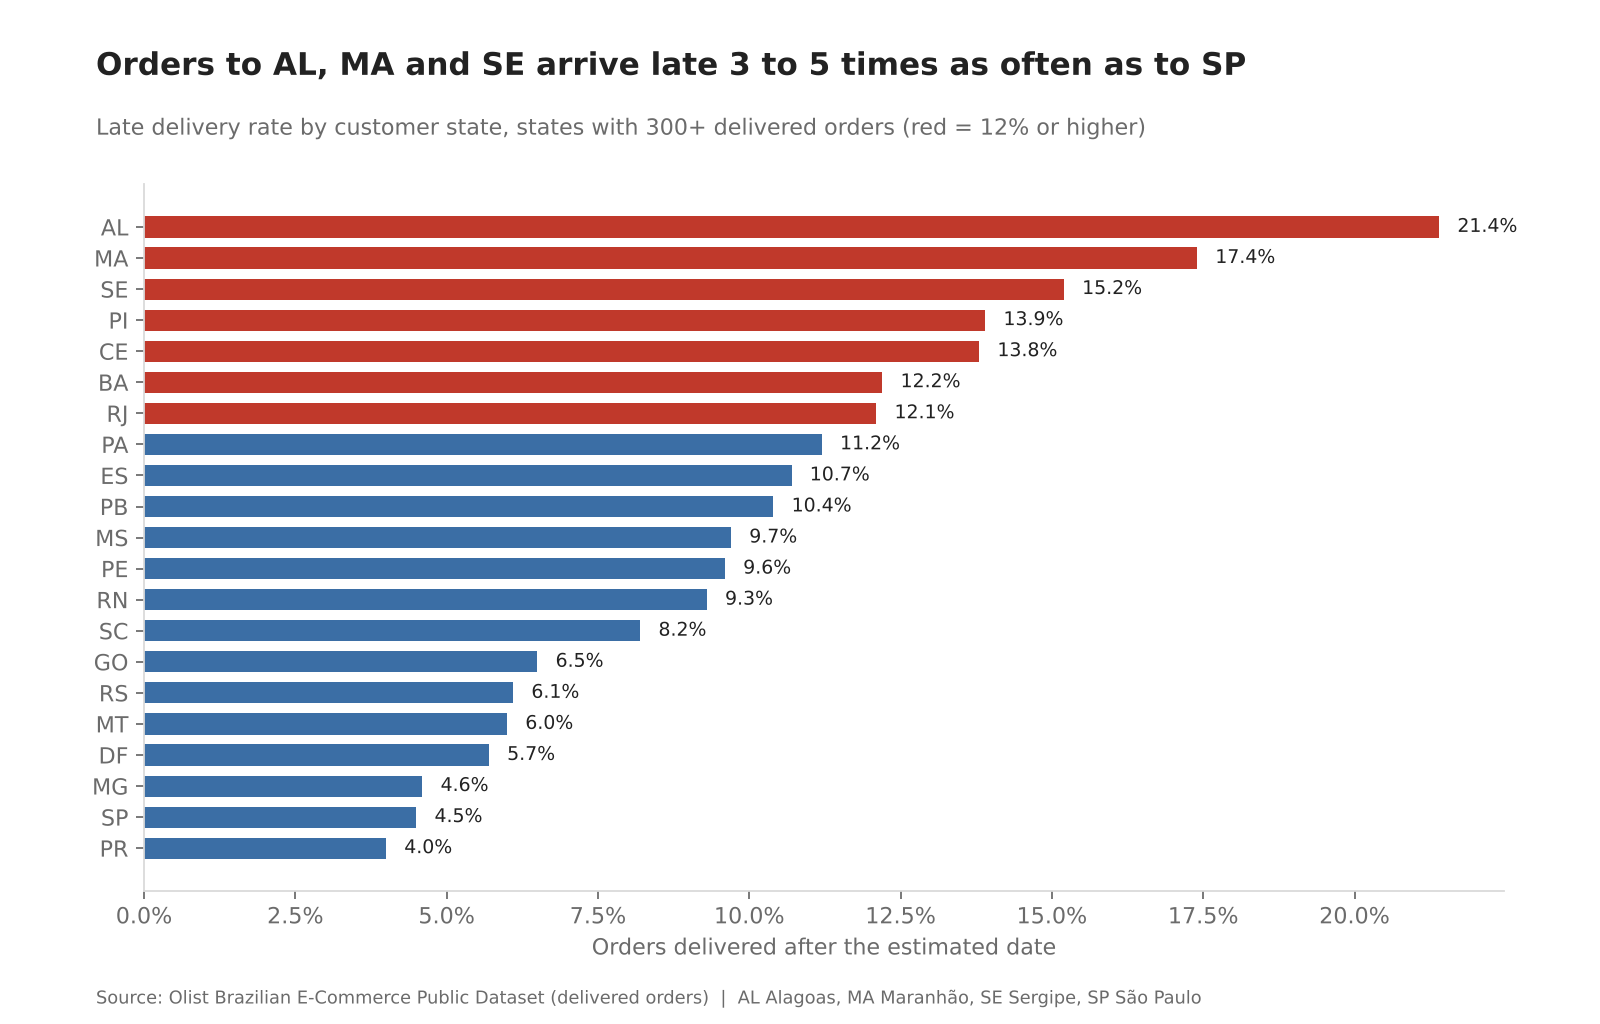

In [15]:
show("05_late_by_state")

Lateness is geographic. Alagoas (21.4% late), Maranhão (17.4%) and Sergipe (15.2%) run 3 to 5 times the rate of São Paulo (4.5%), where the average delivery takes 8.8 days against 24.5 in Alagoas.

## 6. Seller concentration

In [16]:
run("15a_seller_concentration")

,decile,sellers,revenue,revenue_share_pct,cumulative_share_pct
0,1,297,"8,872,848.00",67.12,67.12
1,2,297,"2,006,305.00",15.18,82.29
2,3,297,"1,026,473.00",7.76,90.06
3,4,297,"549,450.00",4.16,94.21
4,5,297,"328,056.00",2.48,96.69
5,6,297,"202,659.00",1.53,98.23
6,7,297,"117,832.00",0.89,99.12
7,8,297,"67,009.00",0.51,99.62
8,9,297,"36,229.00",0.27,99.90
9,10,297,"13,387.00",0.10,100.00


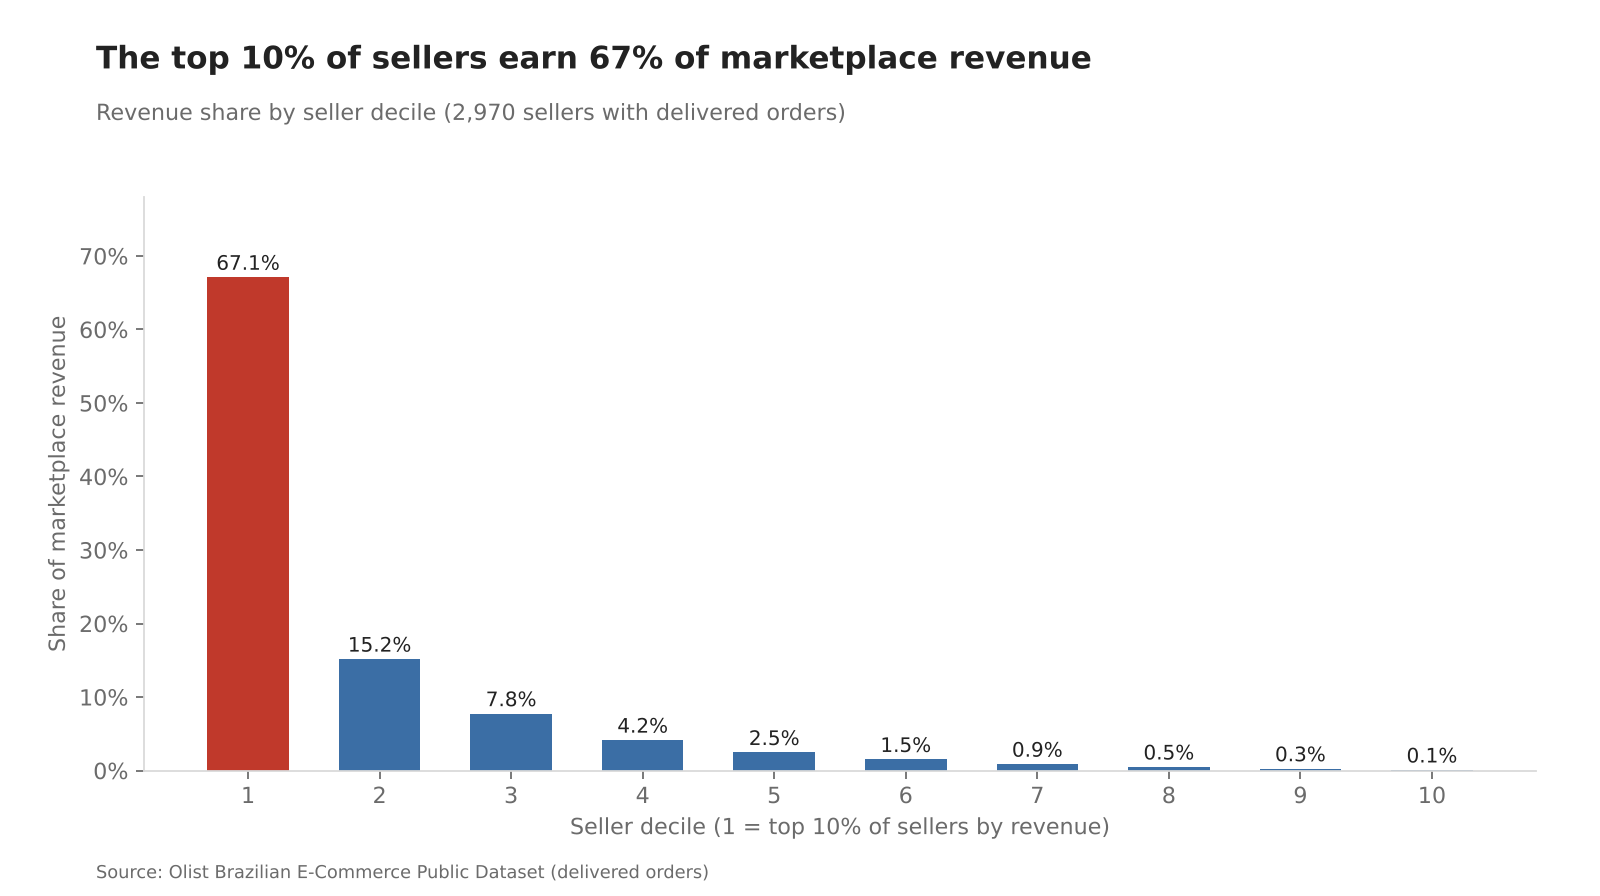

In [17]:
show("06_seller_concentration")

In [18]:
run("15b_top_sellers").head(10)

,seller_id,seller_state,orders,revenue,avg_review_score,late_pct
0,4869f7a5dfa277a7dca6462dcf3b52b2,SP,1124,"226,988.00",4.15,10.50
1,53243585a1d6dc2643021fd1853d8905,BA,348,"217,940.00",4.19,3.40
2,4a3ca9315b744ce9f8e9374361493884,SP,1772,"196,882.00",3.85,9.70
3,fa1c13f2614d7b5c4749cbc52fecda94,SP,578,"190,917.00",4.37,9.20
4,7c67e1448b00f6e969d365cea6b010ab,SP,973,"186,570.00",3.50,9.10
5,7e93a43ef30c4f03f38b393420bc753a,SP,319,"165,981.00",4.36,4.70
6,da8622b14eb17ae2831f4ac5b9dab84a,SP,1311,"159,817.00",4.18,6.60
7,7a67c85e85bb2ce8582c35f2203ad736,SP,1145,"139,659.00",4.28,5.20
8,1025f0e2d44d7041d6cf58b6550e0bfa,SP,910,"138,209.00",4.01,7.90
9,955fee9216a65b617aa5c0531780ce60,SP,1261,"131,837.00",4.20,6.10


The top 10% of sellers (297 of 2,970) earn **67.1%** of revenue, the top 20% earn 82.3%, and the bottom half together earn only 3.3%. The marketplace depends heavily on a small group of sellers, so their fulfilment quality largely determines the customer experience.

## 7. Payments and geography

In [19]:
run("16a_payment_types")

,payment_type,orders,payment_value,value_share_pct,avg_payment,avg_installments
0,credit_card,74297,"12,100,070.00",78.46,162.25,3.50
1,boleto,19191,"2,769,933.00",17.96,144.33,1.00
2,voucher,3679,"343,013.00",2.22,62.45,1.00
3,debit_card,1484,"208,067.00",1.35,140.11,1.00


In [20]:
run("16b_installments")

,installments,orders,orders_pct,avg_order_value
0,11+,331,0.45,357.80
1,1 (paid in full),24639,33.16,95.92
2,2-3,22157,29.82,134.05
3,4-6,15736,21.18,180.95
4,7-10,11434,15.39,332.41


Credit card carries 78.5% of payment value and boleto (a Brazilian bank-slip payment) 18.0%. Two thirds of card orders (66.8%) are split into instalments, and basket size climbs with instalment count: R$96 average for single-payment orders versus R$332 for 7 to 10 instalments.

In [21]:
run("17_geography").head(10)

,state,orders,revenue,revenue_share_pct,avg_order_value,freight_pct_of_revenue
0,SP,40494,"5,066,563.00",38.32,125.12,13.90
1,RJ,12350,"1,759,651.00",13.31,142.48,16.80
2,MG,11354,"1,552,482.00",11.74,136.73,17.20
3,RS,5344,"728,718.00",5.51,136.36,18.20
4,PR,4923,"666,064.00",5.04,135.30,17.40
5,SC,3546,"507,012.00",3.84,142.98,17.40
6,BA,3256,"493,584.00",3.73,151.59,19.80
7,DF,2080,"296,498.00",2.24,142.55,16.70
8,GO,1957,"282,837.00",2.14,144.53,18.20
9,ES,1995,"268,643.00",2.03,134.66,18.20


São Paulo alone is 38.3% of revenue, and São Paulo, Rio de Janeiro and Minas Gerais together account for 63.4%. Freight takes 13.9% of revenue in São Paulo but 24% to 26% in remote states of the north and northeast such as Maranhão (26.3%) and Sergipe (24.2%).

## Summary and recommendations

| Finding | Evidence | Suggested action |
|---|---|---|
| Satisfaction tracks delivery reliability | 2.27 vs 4.29 stars, graded by days late | Set estimates by state from observed delivery times so the promise matches reality |
| Late-delivery hotspots are regional | AL, MA, SE at 15% to 21% vs 4.5% in SP | Review carriers and seller dispatch times for northeast routes |
| One-time buying dominates | 97% of customers order once | Test post-purchase campaigns aimed at the lapsed big spenders (30.9% of revenue) |
| Revenue depends on few sellers | Top 10% earn 67% | Monitor top-seller service levels and reduce dependency risk |
| Growth stalled in 2018 | R$0.9M a month plateau | Volume is the lever, since average order value is flat |

**Limitations.** Observational data from 2016 to 2018, so no causal claims. Revenue excludes freight. Orders with several sellers are attributed to each seller for review metrics. Review scores exist for 95,824 of 96,470 delivered orders.